# Forward–Backward Exponential Smoothing and Its Advantages Over Running Means

## Part I: Approximating the 11-year Sunspot Cycle

In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# read data from the .txt file
sunspot_year, sunspot_month, sunspot = np.loadtxt("sunspot.txt", unpack=True)

# establish a decimal year time axis
sunspot_time = sunspot_year + (sunspot_month - 1) / 12

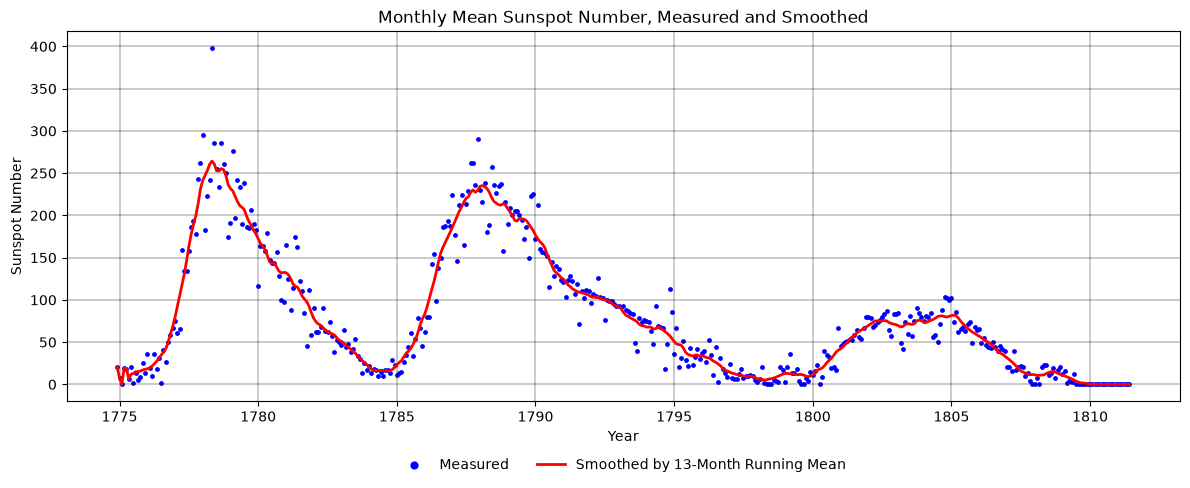

In [11]:
# apply a 13-month running mean 
def smooth_by_running_mean(data, time):
    n = len(time)
    running_mean_13 = data.copy()

    for i in range(6, n - 6):
        mean = (data[i-6] + data[i+6]) / 24

        for j in range(i-5, i+6):
            mean += data[j] / 12

        running_mean_13[i] = mean

    return running_mean_13

sunspot_number_running_mean_smoothing = smooth_by_running_mean(sunspot, sunspot_time)

# plot the data
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(sunspot_time, sunspot, s=6, color="blue", label="Measured")
ax.plot(sunspot_time, sunspot_number_running_mean_smoothing, linewidth=2, color="red", label="Smoothed by 13-Month Running Mean")
ax.set_title("Monthly Mean Sunspot Number, Measured and Smoothed")
ax.set_xlabel("Year")
ax.set_ylabel("Sunspot Number")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, markerscale=2, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()


In [4]:
# apply forward-backward exponential smoothing
def forward_backward_exponential_smoothing(measurements, alpha):
    f_smoothed_points = np.zeros(measurements.size)
    b_smoothed_points = np.zeros(measurements.size)

    # run forward exponential smoothing
    f_smoothed_points[0] = measurements[0]
    for i in range(1, measurements.size):
        f_smoothed_points[i] = f_smoothed_points[i - 1] + alpha * (measurements[i] - f_smoothed_points[i-1])
    
    # run backward exponential smoothing
    b_smoothed_points[b_smoothed_points.size - 1] = f_smoothed_points[f_smoothed_points.size - 1]
    for i in range(measurements.size - 2, -1, -1):
        b_smoothed_points[i] = b_smoothed_points[i + 1] + alpha * (f_smoothed_points[i] - b_smoothed_points[i + 1])

    return b_smoothed_points

Intersection: α = 0.31


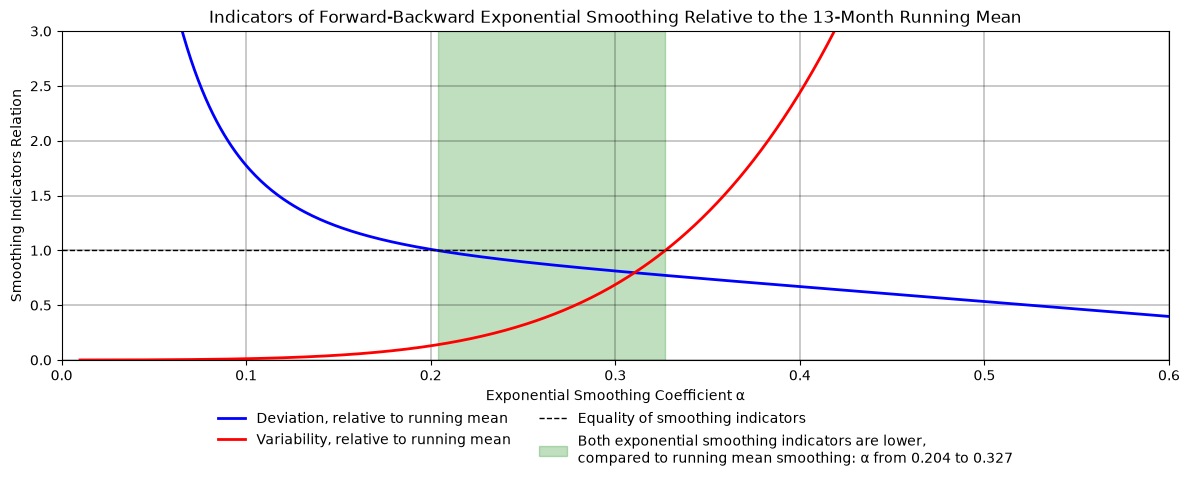

In [48]:
# find the indicators of smoothing performance
def find_smoothing_indicators(measured, estimated):
   deviation = np.sum((measured - estimated)**2)
   variability = np.sum((estimated[2:] - 2*estimated[1:-1] + estimated[:-2])**2)


   return deviation, variability

# determine indicators of smoothing effectiveness for 13-running mean smoothing
running_mean_dev, running_mean_var = find_smoothing_indicators(sunspot, sunspot_number_running_mean_smoothing)

# determine indicators of smoothing effectiveness for exponential smoothing
# with alpha ranging from 0,01 to 1,00
alpha_values = np.round(np.arange(0.01, 1.0001, 0.001), 3)
fb_dev = np.zeros(alpha_values.size)
fb_var = np.zeros(alpha_values.size)
for k, alpha in enumerate(alpha_values):
   fb_exp_smoothed_points  = forward_backward_exponential_smoothing(sunspot, alpha)
   fb_dev[k], fb_var[k] = find_smoothing_indicators(sunspot, fb_exp_smoothed_points)
   if np.abs((fb_dev[k] / running_mean_dev) - (fb_var[k] / running_mean_var)) < 0.005:
      print(f"Intersection: α = {alpha}")

# alpha values where both indicators for the exponential smoothing are lower than for the 13-month running mean
better_alphas = alpha_values[(fb_dev < running_mean_dev) & (fb_var < running_mean_var)]

# plot both indicators relative to the 13-month running mean
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(alpha_values, fb_dev / running_mean_dev, linewidth=2, color="blue", label="Deviation, relative to running mean")
ax.plot(alpha_values, fb_var / running_mean_var, linewidth=2, color="red", label="Variability, relative to running mean")
ax.axhline(1, color="black", linewidth=1, linestyle="--", label="Equality of smoothing indicators")
ax.axvspan(better_alphas.min(), better_alphas.max(), color="green", alpha=0.25, label=f"Both exponential smoothing indicators are lower, \ncompared to running mean smoothing: α from {better_alphas.min()} to {better_alphas.max()}")
ax.set_title("Indicators of Forward-Backward Exponential Smoothing Relative to the 13-Month Running Mean")
ax.set_xlabel("Exponential Smoothing Coefficient α")
ax.set_ylabel("Smoothing Indicators Relation")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 3)
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

In [49]:
fb_dev_0_31, fb_var_0_31 = find_smoothing_indicators(sunspot, forward_backward_exponential_smoothing(sunspot, 0.31))
print(f"Indicators of smoothing effectiveness for 13-running mean smoothing: deviation indicator = {running_mean_dev}, variability indicator = {running_mean_var}")
print(f"Indicators of smoothing effectiveness for forward-backward exponential smoothing: deviation indicator = {fb_dev_0_31}, variability indicator = {fb_var_0_31}")


Indicators of smoothing effectiveness for 13-running mean smoothing: deviation indicator = 143332.93960069443, variability indicator = 2797.099374999998
Indicators of smoothing effectiveness for forward-backward exponential smoothing: deviation indicator = 114152.35379481126, variability indicator = 2213.9140728919947


In [50]:
'''# find alpha values that improve both Assignment 3 smoothing indicators
def find_better_alpha(measurements, time, running_mean, alpha_values=None):
    measurements = np.asarray(measurements, dtype=float)
    time = np.asarray(time)
    running_mean = np.asarray(running_mean, dtype=float)

    if measurements.ndim != 1 or measurements.size < 3:
        raise ValueError("measurements must be a one-dimensional array with at least 3 values")
    if time.shape != measurements.shape or running_mean.shape != measurements.shape:
        raise ValueError("time and running_mean must have the same shape as measurements")
    if not (np.all(np.isfinite(measurements)) and np.all(np.isfinite(running_mean))):
        raise ValueError("measurements and running_mean must contain only finite values")

    if alpha_values is None:
        alpha_values = np.linspace(0.01, 1.0, 1000)
    else:
        alpha_values = np.asarray(alpha_values, dtype=float)
    if (alpha_values.ndim != 1 or alpha_values.size == 0
            or not np.all(np.isfinite(alpha_values))
            or np.any((alpha_values < 0) | (alpha_values > 1))):
        raise ValueError("alpha_values must be a non-empty 1D array of values between 0 and 1")

    def indicators(estimated):
        deviation = np.sum((measurements - estimated) ** 2)
        variability = np.sum((estimated[2:] - 2 * estimated[1:-1] + estimated[:-2]) ** 2)
        return deviation, variability

    baseline_deviation, baseline_variability = indicators(running_mean)
    if baseline_deviation <= 0 or baseline_variability <= 0:
        raise ValueError("running_mean indicators must be positive for normalized comparison")

    deviations = []
    variabilities = []
    candidates = []
    for alpha in alpha_values:
        estimated = forward_backward_exponential_smoothing(measurements, alpha)
        deviation, variability = indicators(estimated)
        deviations.append(deviation)
        variabilities.append(variability)
        if deviation < baseline_deviation and variability < baseline_variability:
            score = deviation / baseline_deviation + variability / baseline_variability
            candidates.append((score, alpha, deviation, variability, estimated))

    if not candidates:
        raise ValueError("No tested alpha improves both indicators over the 13-month running mean")

    # Among candidates improving both indicators, minimize their equally weighted normalized sum.
    _, best_alpha, best_deviation, best_variability, best_smoothed = min(
        candidates, key=lambda candidate: candidate[0]
    )
    print(f"13-month running mean: deviation = {baseline_deviation:.3f}, variability = {baseline_variability:.3f}")
    print(f"Selected alpha = {best_alpha:.3f}")
    print(f"Forward-backward exponential smoothing: deviation = {best_deviation:.3f}, variability = {best_variability:.3f}")
    print(f"Improvement: deviation = {(1 - best_deviation / baseline_deviation) * 100:.2f}%, "
          f"variability = {(1 - best_variability / baseline_variability) * 100:.2f}%")

    fig, axes = plt.subplots(3, 1, figsize=(12, 11))
    axes[0].plot(time, measurements, color='gray', alpha=0.5, label='Original Sunspot Data')
    axes[0].plot(time, running_mean, color='blue', label='13-Month Running Mean')
    axes[0].plot(time, best_smoothed, color='red', label=f'Forward-Backward Exponential, alpha = {best_alpha:.3f}')
    axes[0].set_ylabel('Sunspot Number')
    axes[0].legend()
    axes[0].grid()

    axes[1].plot(alpha_values, deviations, color='purple')
    axes[1].axhline(baseline_deviation, color='blue', linestyle='--', label='13-month running mean')
    axes[1].axvline(best_alpha, color='red', linestyle=':', label=f'Selected alpha = {best_alpha:.3f}')
    axes[1].set_ylabel('Deviation indicator')
    axes[1].legend()
    axes[1].grid()

    axes[2].plot(alpha_values, variabilities, color='darkgreen')
    axes[2].axhline(baseline_variability, color='blue', linestyle='--', label='13-month running mean')
    axes[2].axvline(best_alpha, color='red', linestyle=':', label=f'Selected alpha = {best_alpha:.3f}')
    axes[2].set_xlabel('Smoothing constant alpha')
    axes[2].set_ylabel('Variability indicator')
    axes[2].legend()
    axes[2].grid()
    fig.tight_layout()
    plt.show()

    return best_alpha, best_smoothed

sunspot_best_alpha, sunspot_number_fb_expo_smoothing = find_better_alpha(
    sunspot, sunspot_time, sunspot_number_running_mean_smoothing
)'''

'# find alpha values that improve both Assignment 3 smoothing indicators\ndef find_better_alpha(measurements, time, running_mean, alpha_values=None):\n    measurements = np.asarray(measurements, dtype=float)\n    time = np.asarray(time)\n    running_mean = np.asarray(running_mean, dtype=float)\n\n    if measurements.ndim != 1 or measurements.size < 3:\n        raise ValueError("measurements must be a one-dimensional array with at least 3 values")\n    if time.shape != measurements.shape or running_mean.shape != measurements.shape:\n        raise ValueError("time and running_mean must have the same shape as measurements")\n    if not (np.all(np.isfinite(measurements)) and np.all(np.isfinite(running_mean))):\n        raise ValueError("measurements and running_mean must contain only finite values")\n\n    if alpha_values is None:\n        alpha_values = np.linspace(0.01, 1.0, 1000)\n    else:\n        alpha_values = np.asarray(alpha_values, dtype=float)\n    if (alpha_values.ndim != 1 or 

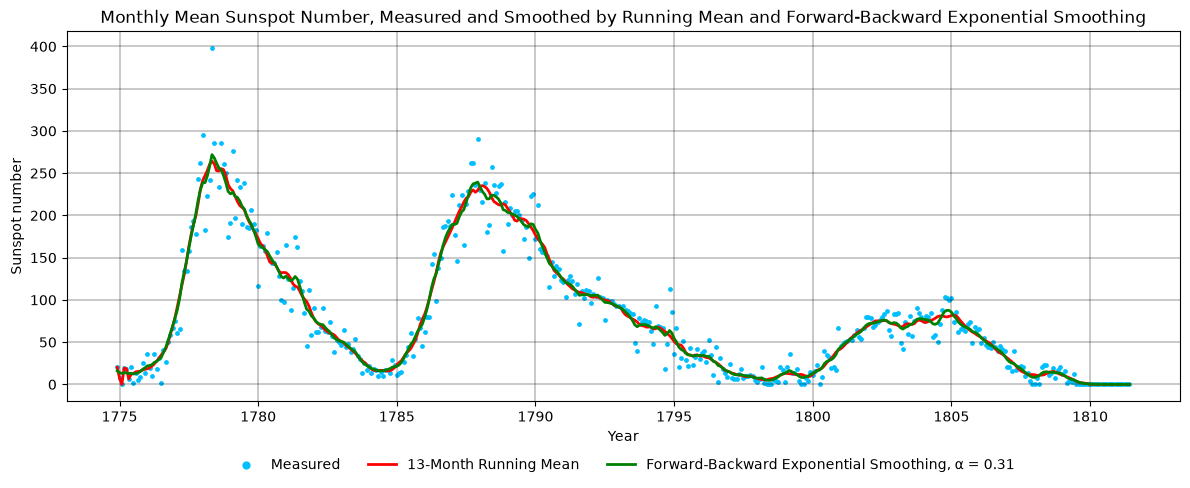

In [ ]:
# plot the monthly data, the 13-month running mean and forward-backward exponential smoothing
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(sunspot_time, sunspot, s=6, color="deepskyblue", label="Measured")
ax.plot(sunspot_time, sunspot_number_running_mean_smoothing, linewidth=2, color="red", label="13-Month Running Mean")
ax.plot(sunspot_time, forward_backward_exponential_smoothing(sunspot, 0.31), linewidth=2, color="green", label=f"Forward-Backward Exponential Smoothing, α = {0.31}")
ax.set_title("Monthly Mean Sunspot Number, Measured and Smoothed by Running Mean and Forward-Backward Exponential Smoothing")
ax.set_xlabel("Year")
ax.set_ylabel("Sunspot number")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, markerscale=2, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
plt.show()

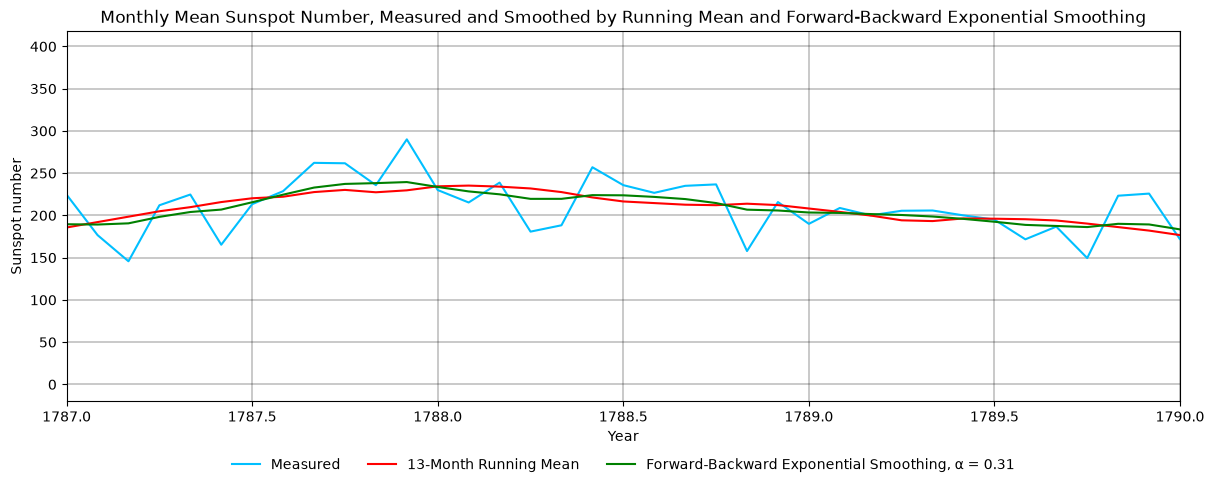

In [62]:
# plot the monthly data, the 13-month running mean and forward-backward exponential smoothing
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sunspot_time, sunspot, linewidth=1.5, color="deepskyblue", label="Measured")
ax.plot(sunspot_time, sunspot_number_running_mean_smoothing, linewidth=1.5, color="red", label="13-Month Running Mean")
ax.plot(sunspot_time, forward_backward_exponential_smoothing(sunspot, 0.31), linewidth=1.5, color="green", label=f"Forward-Backward Exponential Smoothing, α = {0.31}")
ax.set_title("Monthly Mean Sunspot Number, Measured and Smoothed by Running Mean and Forward-Backward Exponential Smoothing")
ax.set_xlabel("Year")
ax.set_ylabel("Sunspot number")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=False, markerscale=2, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
ax.set_xlim(1787, 1790)
plt.show()

## Part II: 3D Surface Reconstruction Under Noise

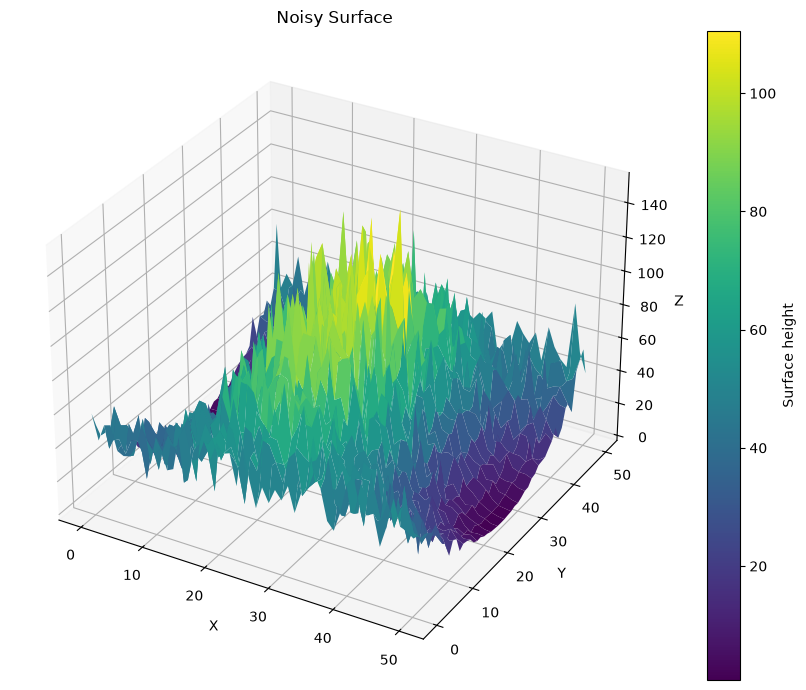

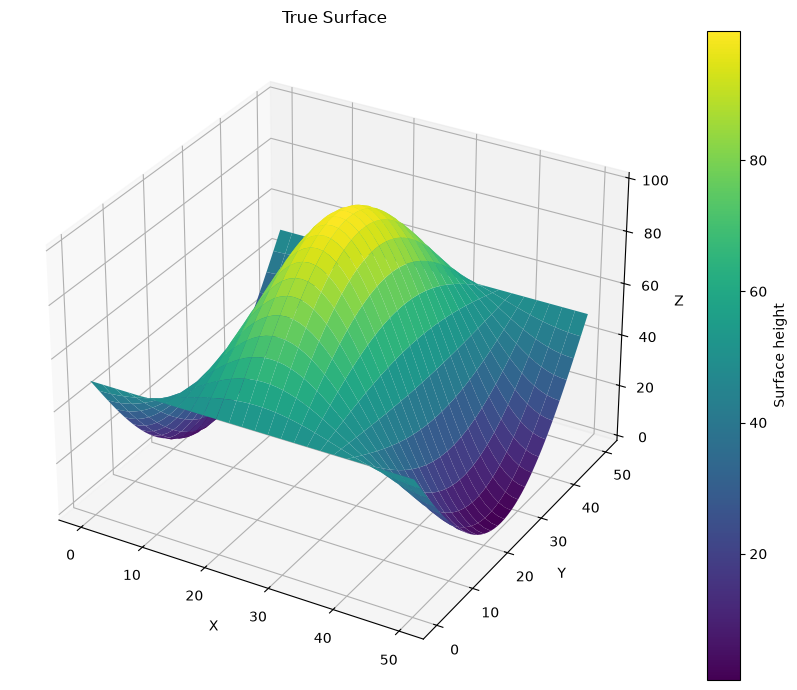

In [ ]:
# load surface data from the .txt files
noisy_surface = np.loadtxt("noisy_surface.txt")
true_surface = np.loadtxt("true_surface.txt")

# plot the surfaces
def plot_surface(surface, title, cmap="viridis"):
    x = np.arange(surface.shape[1])
    y = np.arange(surface.shape[0])
    X, Y = np.meshgrid(x, y)
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    surface_plot = ax.plot_surface(X, Y, surface, cmap=cmap)
    fig.colorbar(surface_plot, ax=ax, label="Surface height")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_surface(noisy_surface, "Noisy Surface")
plot_surface(true_surface, "True Surface")

In [ ]:
'''# flatten the matrices to 1D arrays for smoothing
noisy_surface_flat = noisy_surface.reshape(-1)
true_surface_flat = true_surface.reshape(-1)

# create an array of devations
deviations = noisy_surface_flat - true_surface_flat

# find variance of the deviations
variance = np.var(deviations)
print(f"Variance of the deviations between noisy and true surface: {variance:.6f}")'''


Variance of the deviations between noisy and true surface: 129.057767


In [81]:
# variance of the deviation between the noisy and the true surfaces
def find_variance(estimated_surface, true_surface):
    deviation = (estimated_surface - true_surface).reshape(-1)
    n_points = deviation.size
    deviation_mean = np.sum(deviation) / n_points
    deviation_variance = np.sum((deviation - deviation_mean)**2) / n_points
    return deviation_variance

deviation_variance = find_variance(noisy_surface, true_surface)
print(f"Variance of the deviation between the noisy and the true surface: {deviation_variance:.3f}")

Variance of the deviation between the noisy and the true surface: 129.058


In [73]:
# forward exponential smoothing
def forward_exp_smoothing(measurements, alpha):
   smoothed_points = np.zeros(measurements.size)
   smoothed_points[0] = measurements[0]
  
   for i in range(1, measurements.size):
       smoothed_points[i] = smoothed_points[i - 1] + alpha * (measurements[i] - smoothed_points[i-1])
  
   return smoothed_points


# backward exponential smoothing on the forward exponential smoothing
def backward_exp_smoothing(f_values, alpha):
   b_values = np.zeros(f_values.size)
   b_values[b_values.size - 1] = f_values[f_values.size - 1]
   for i in range(b_values.size - 2, -1, -1):
       b_values[i] = b_values[i + 1] + alpha * (f_values[i] - b_values[i + 1])
   return b_values


# apply forward-backward exponential smoothing to the noisy surface
def exp_smoothing_surface(surface, alpha):
   smoothed_surface = surface.copy()

   for i in range(smoothed_surface.shape[0]):
       smoothed_surface[i, :] = forward_exp_smoothing(smoothed_surface[i, :], alpha)   # step 1: forward smoothing of the rows
       smoothed_surface[i, :] = backward_exp_smoothing(smoothed_surface[i, :], alpha)  # step 2: backward smoothing of the rows

   for i in range(smoothed_surface.shape[1]):
       smoothed_surface[:, i] = forward_exp_smoothing(smoothed_surface[:, i], alpha)   # step 3: forward smoothing of the columns
       smoothed_surface[:, i] = backward_exp_smoothing(smoothed_surface[:, i], alpha)  # step 4: backward smoothing of the columns

   return smoothed_surface


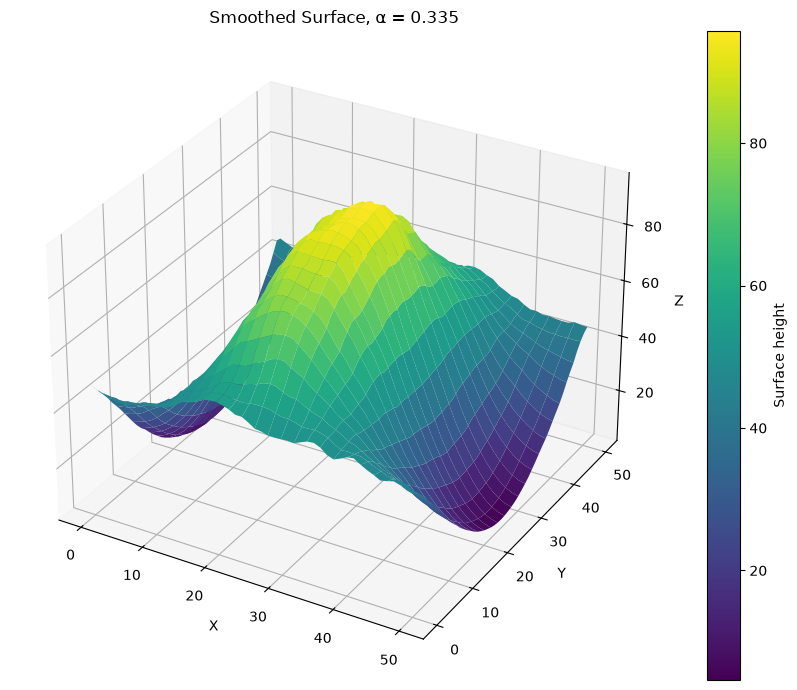

In [ ]:
ALPHA_SURFACE = 0.335
smoothed_surface = exp_smoothing_surface(noisy_surface, ALPHA_SURFACE)
plot_surface(smoothed_surface, f"Smoothed Surface, α = {ALPHA_SURFACE},\nVariance of the deviation between the smoothed and the true surface is ")

In [82]:
# variance of the deviation between the smoothed and the true surfaces
deviation_variance_smoothed = find_variance(smoothed_surface, true_surface)
print(f"Variance of the deviation between the smoothed and the true surface: {deviation_variance_smoothed:.3f}")

Variance of the deviation between the smoothed and the true surface: 6.533


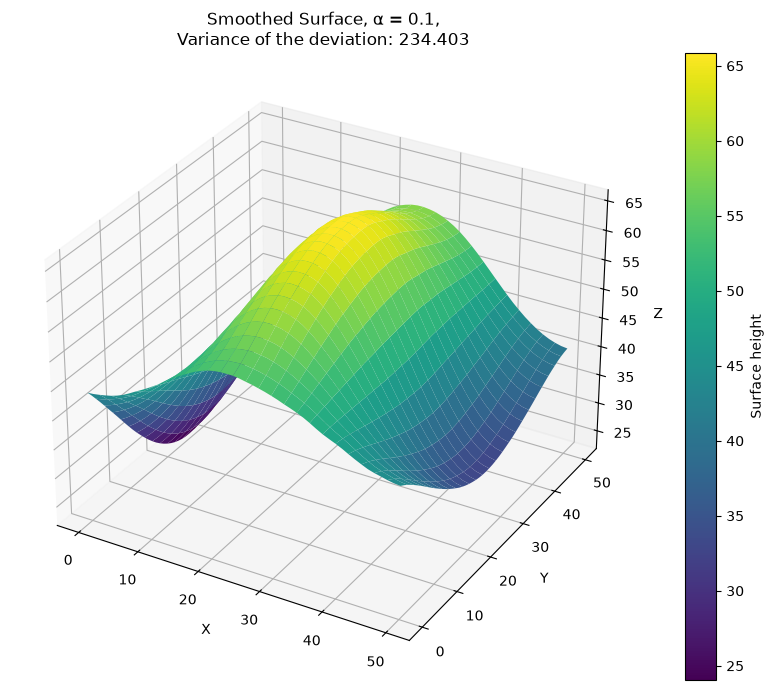

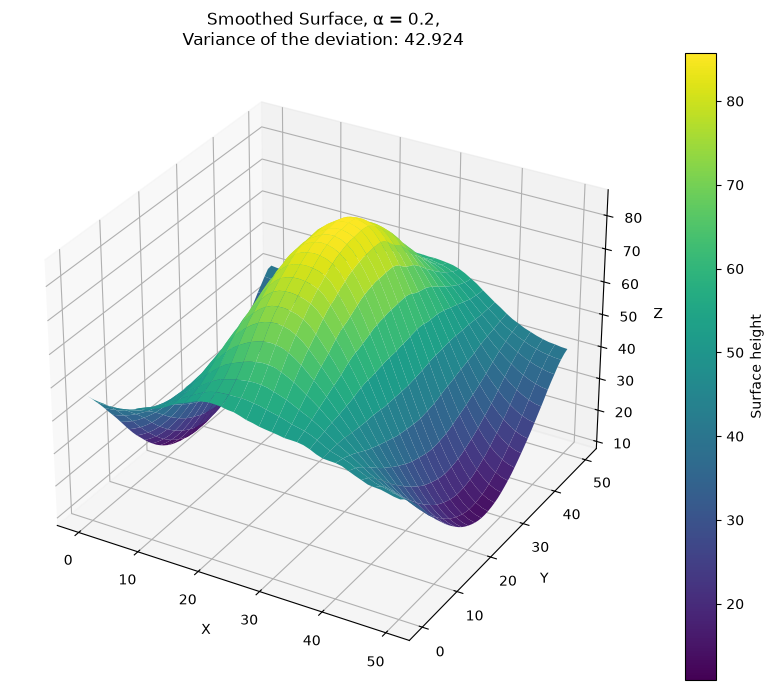

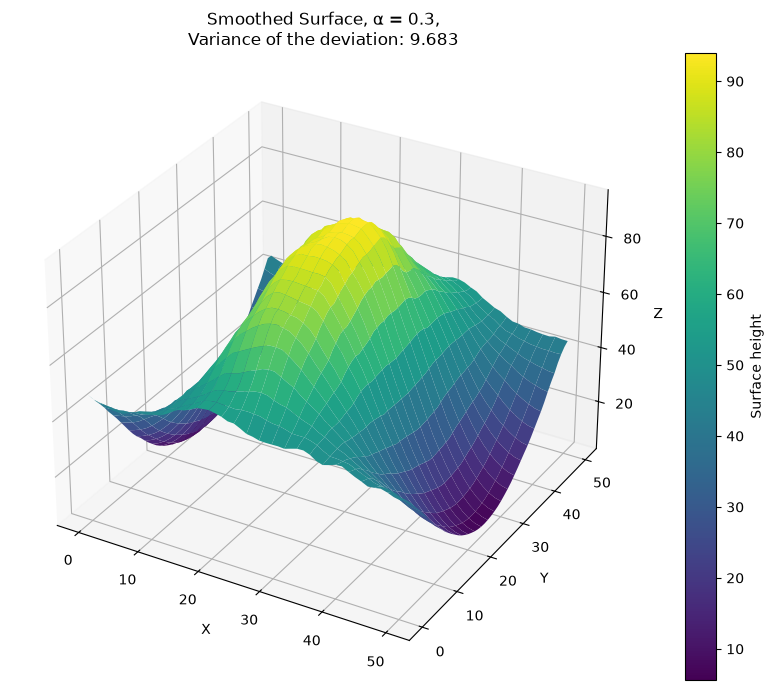

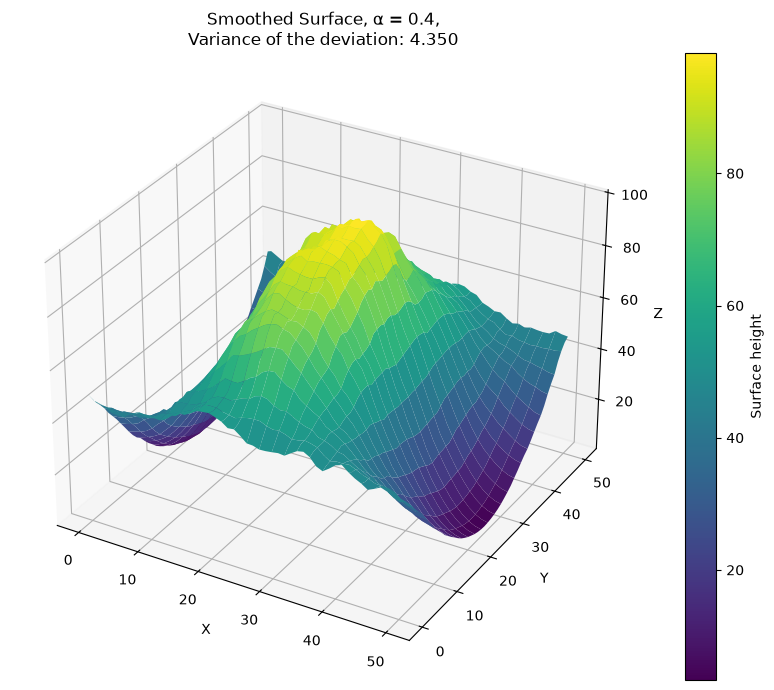

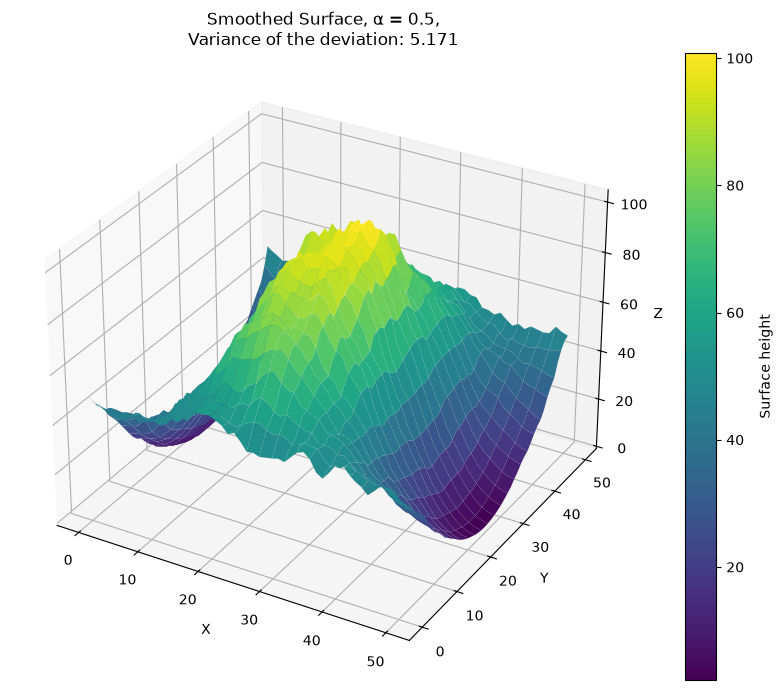

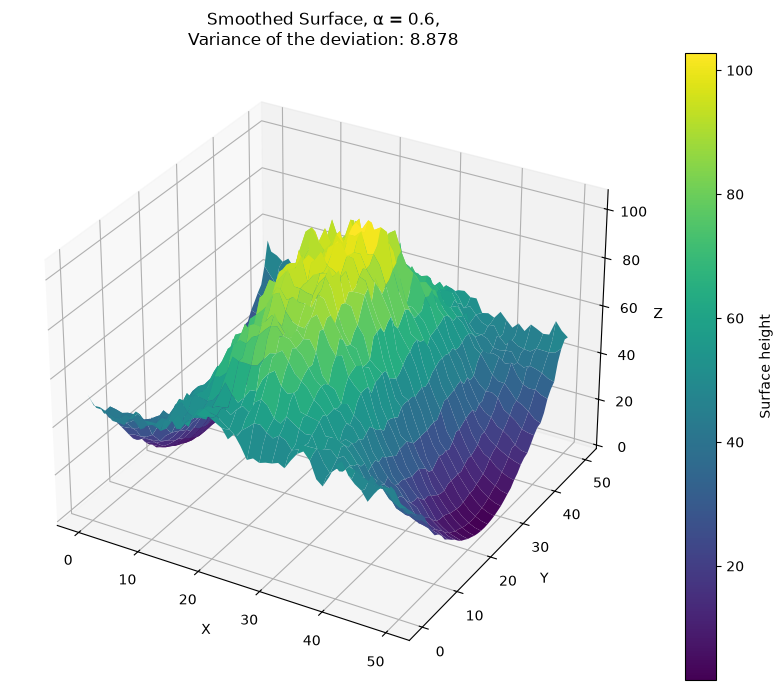

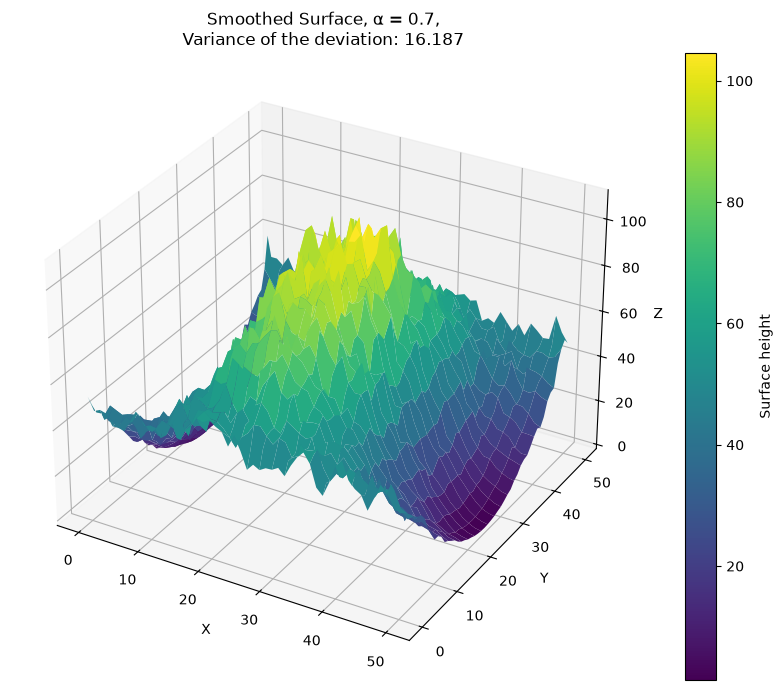

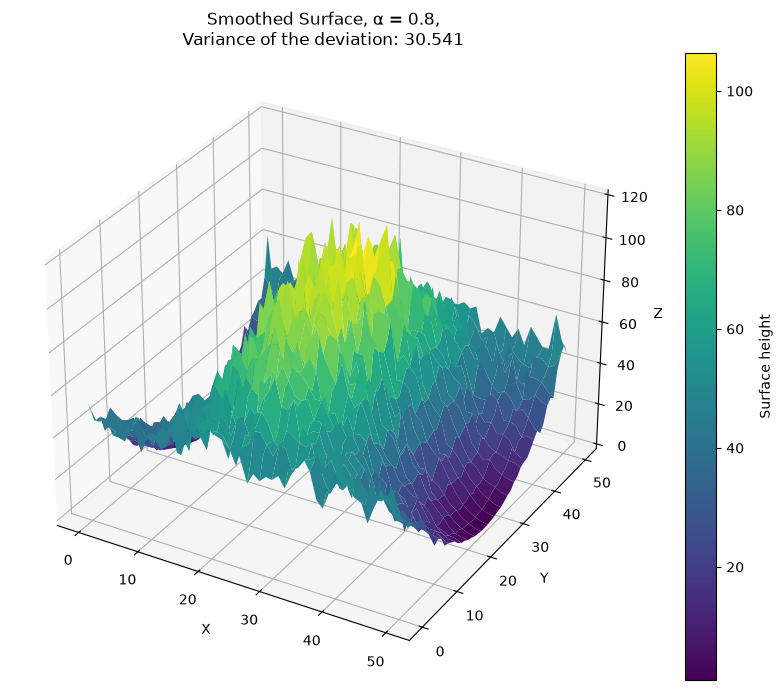

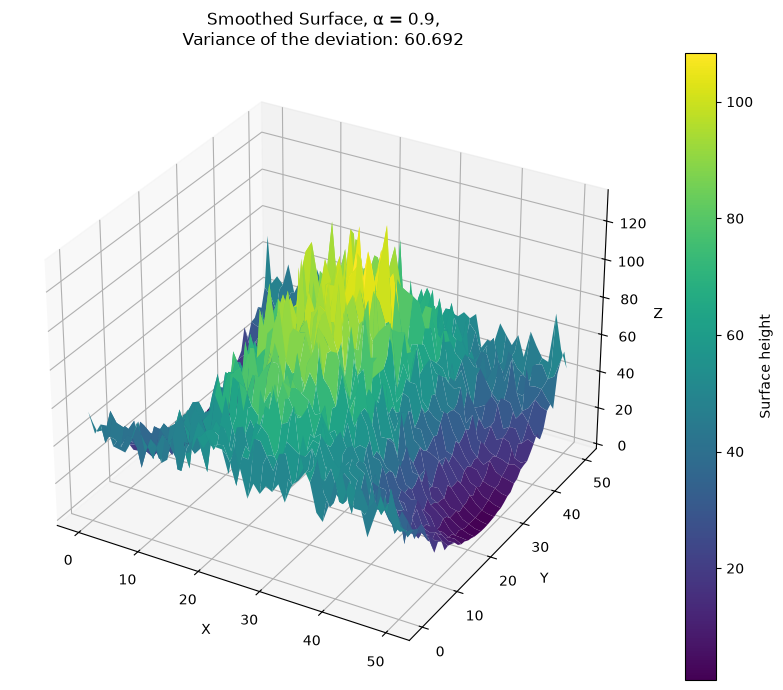

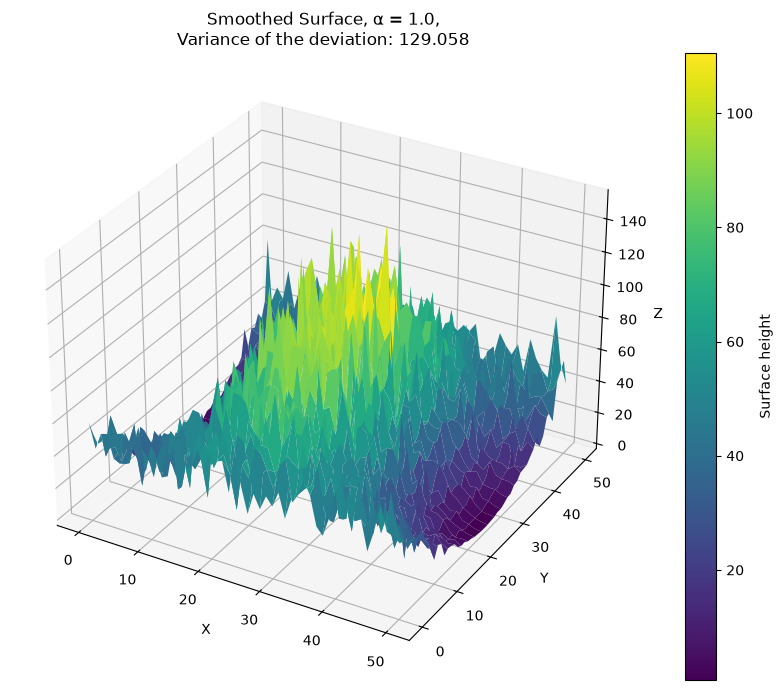

In [86]:
alpha_surface_values = np.arange(0.1, 1.1, 0.1)
for alpha in alpha_surface_values:
    some_smoothed_surface = exp_smoothing_surface(noisy_surface, alpha)
    deviation_variance_of_some_surface = find_variance(some_smoothed_surface, true_surface)
    plot_surface(some_smoothed_surface, f"Smoothed Surface, α = {alpha:.1f},\nVariance of the deviation: {deviation_variance_of_some_surface:.3f}")